## AI declaration

In this assignment I have used Copilot AI to help some coding aspects, and as sparring partner to implement my thoughts to code

# option B - Tune in!

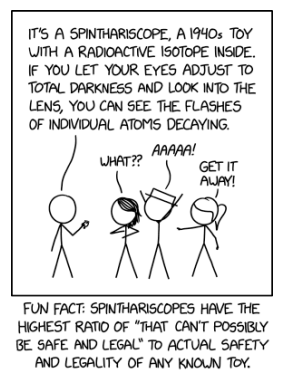

## import packages

In [13]:
import numpy as np
import matplotlib.pyplot as plt
# sound
from scipy.io import wavfile
from scipy.ndimage import uniform_filter1d
from pydub import AudioSegment
# machine learning
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

### convert sound from stereo to mono

In [2]:
# import the sound
sound_file = AudioSegment.from_wav('sounds\TinySOL\Strings\Violin\ordinario\Vn-ord-B3-ff-4c-T17u.wav')
# set mono channel
sound_file = sound_file.set_channels(1)
# save the result
sound_file.export("mono_outfile.wav", format="wav")

# save the samplerate and the data from the sound
samplerate, audio = wavfile.read('mono_outfile.wav') # samplerate is samples / s

### plot the sound in the time domain

Text(0, 0.5, 'Amplitude')

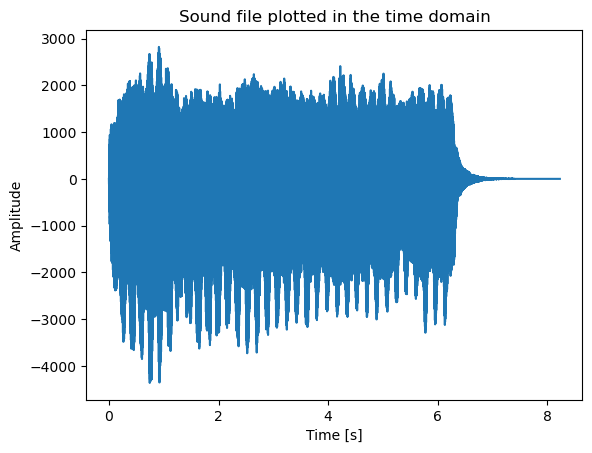

In [3]:
# make the time vector: the duration:
time_dur = audio.shape[0]/samplerate
# the time vector from 0 to duration, with data.shape datapoints
time = np.linspace(0,time_dur,audio.shape[0])

# plot the sound file in the time domain
plt.plot(time,audio)
plt.title('Sound file plotted in the time domain')
plt.xlabel('Time [s]')
plt.ylabel('Amplitude')

### plot the spectrum

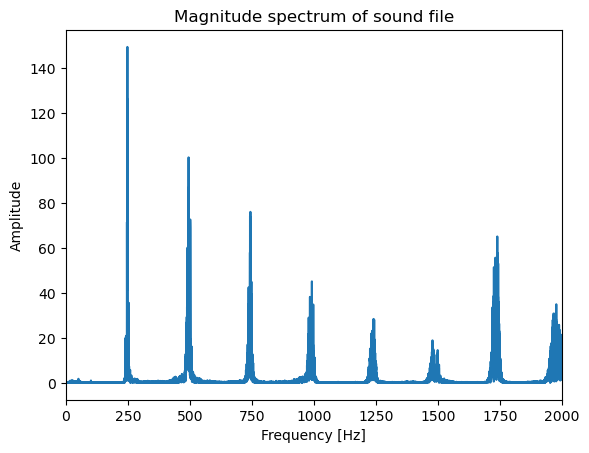

In [4]:
# convert signal to the frequency domain
def make_spectrum(signal, fs):
    # compute discrete fourier transform (complex-valued)
    Y = np.fft.fft(signal) # Fourier

    # normalise fft by number of samples
    Y = Y / len(Y)

    # number of samples
    n = signal.size

    # sampling period in seconds
    d = (1/fs)

    # frequency axis
    freq = np.fft.fftfreq(n, d)

    # returning the complex spectrum and corresponding frequencies
    return Y, freq 

# make spectrum of our sound file
faudio, ffreq = make_spectrum(audio, samplerate)

# convert the magnitude to real, positive numbers only 
magnitude = 2 * np.abs(faudio) # multiply by two because we are disregarding the negative frequencies, but need to still take them into account as positive frequencies.

# positive mask (we don't want negative frequencies since they don't actually exist)
pos_mask = ffreq >= 0

# use the mask on the computed spectrum
ffreq_pos = ffreq[pos_mask]
mag_pos = magnitude[pos_mask]

# plot the magnitude spectrum
plt.figure()
plt.title('Magnitude spectrum of sound file')
plt.xlabel('Frequency [Hz]')
plt.ylabel('Amplitude')
plt.xlim(0,2000) # different zooms for each audio preferred
plt.plot(ffreq_pos,mag_pos)

next step took a lot of considerations. I went through testing of autocorrelation, cepstrum analysis, harmonic product spectrum before finally landing on YIN analysis.

When testing the autocorrelation, it was very good because it finds periods directly in the time domain, and therefore works most of the time. However, I found that it didn't work properly for instruments where the harmonics were considerable larger than the fundamental frequency, because then those harmonics have such prominent periods that it drowns the periodicity of the fundamental frequency.

Cepstrum analysis was the next idea. This was discarded pretty quickly, because even though it is a very good analysis at times, it is not good for instruments where there is a lot of noise, and if the fundamental frequency is high, it can have trouble finding it.

The harmonic product spectrum seemed to work pretty good for isntruments where the harmonics were more prominent than the fundamental frequency. But if the fundamental frequency is too weak, it still might show a harmonic frequency as the fundamental frequency.

And so, I landed on YIN analysis. This analysis utilises some of the same aspects as autocorrelation, but extends it. Finds the first point under a threshold, given a max error from original signal, which is the assumed f0.

Another viable method of determining the fundamental frequency would be to find the periodicity between the harmonics - since they are periodic with the same width as the fundamental frequency, this would work in most cases

## YIN analysis to find f0

Best tau (the period) = 178 samples
Min cmndf = 0.06
f0 = 247.75 Hz


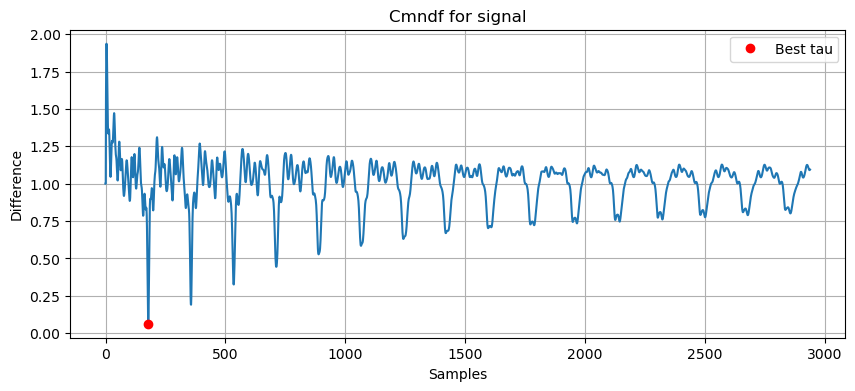

In [5]:
# YIN function
def yin(signal, fs, fmin=15, fmax=8000): # signal (audio, time domain), fs=samplerate, fmin, fmax is the range within we want to find our fundamental frequency (in Hz)
    # preprocessing the signal. 
    signal = signal - np.mean(signal) # removes DC offset to get more reliable difference function
    signal = signal / (np.std(signal) + 1e-12) # scaling signal to unit variance as to make threshold more robust

    # defines tau interval - this is the lag allowed (time shift when doing the analysis), given in samples
    # converting interval from Hz to lags (samples)
    # a period T = 1/f corresponds to tau = fs/f samples
    tau_min = int(fs/fmax)
    tau_max = int(fs/fmin)
    
    d = np.zeros(tau_max) # difference function. insert values for each lag d[tau]

    # difference function 
    # d[tau] is small when signal aligns well with the tau-shifted signal. 
    # Valleys therefore occurs when difference is low, which is when the signal has been shifted a whole period
    for tau in range(1, tau_max):
        diff = signal[:-tau] - signal[tau:] # comparing signal with itself shifted by tau samples
        d[tau] = np.sum(diff**2) # finding the difference between the 'original' signal and the 'tau shifted' signal
        # /\ error of shifted signal. The smaller, the better alignment

    # cumulative mean normalised diference function
    cmndf = np.zeros(tau_max) # same as the difference function above
    cmndf[0] = 1 # necessary for YIN since when tau=0, it is a perfect fit but not valid since there is no lag. Also removes the bias towards the smaller lags (due to running sum)
    
    running_sum = 0 

     # find cmndf for each lag
    for tau in range(1, tau_max):
        running_sum += d[tau] # adding error values together, needed for cmndf normalisation

    
        if running_sum > 0: # ensure no division by 0
            cmndf[tau] = d[tau] * tau / running_sum # normalise d[tau] by the average difference over all smaller lags, minimising bias towards smaller lags


    # finding the best tau (best lag)
    threshold = 0.1 # when tau gets below threshold, that is the assumed fundamental frequency

    best_tau = None

    for tau in range(tau_min, tau_max):
        if cmndf[tau] < threshold: # find the point at which tau reaches threshold (first period that is periodic enough)

            while tau+1 < tau_max and cmndf[tau+1] < cmndf[tau]: # finds the lowest point of the valley, not just when it reaches threshold
                tau+=1
    
            best_tau = tau
            break

    # if tau never goes below threshold:
    if best_tau is None:
        best_tau = np.argmin(cmndf[tau_min:tau_max]) + tau_min 
        # first limit search to predefined interval. finds the minimum, which is the point of best periodicity (the sample number that assumed correlates to f0). 
        # /\ Also adding the offset back on (tau_min) (removed it when defining limits to tau)


    # plot the cmndf
    plt.figure(figsize=(10,4))
    plt.title('Cmndf for signal')
    plt.xlabel('Samples')
    plt.ylabel('Difference')
    plt.plot(cmndf)
    plt.plot(best_tau, cmndf[best_tau], 'ro', label = 'Best tau')
    plt.legend()
    plt.grid()

    print(f'Best tau (the period) = {best_tau} samples') # the period
    print(f'Min cmndf = {cmndf[best_tau]:.2f}') # the difference at that period
    print(f'f0 = {fs/best_tau:.2f} Hz') #fundamental frequency

    return fs/best_tau, cmndf
        
f0, cmndf = yin(audio, samplerate)
instrument_features_dic = {'f0': f0}

above, I've made the YIN algorithm.

The red dot is the point at which the difference is lowest after reaching the threshold of 0.1, and therefore the assumed fundamental frequency, given in samples of the audio sample.

The fundamental frequency is also printed below the cell, in Hz

## Find the note

In [ ]:
# note dictionary that contains the notes from C, 0th octave (16.35 Hz) to B, 8th octave(7902 Hz)
note_dic = {
    "C0": 16.35,   "C#0": 17.32,   "D0": 18.35,   "D#0": 19.45,
    "E0": 20.60,   "F0": 21.83,    "F#0": 23.12,  "G0": 24.50,
    "G#0": 25.96,  "A0": 27.50,    "A#0": 29.14,  "B0": 30.87,

    "C1": 32.70,   "C#1": 34.65,   "D1": 36.71,   "D#1": 38.89,
    "E1": 41.20,   "F1": 43.65,    "F#1": 46.25,  "G1": 49.00,
    "G#1": 51.91,  "A1": 55.00,    "A#1": 58.27,  "B1": 61.74,

    "C2": 65.41,   "C#2": 69.30,   "D2": 73.42,   "D#2": 77.78,
    "E2": 82.41,   "F2": 87.31,    "F#2": 92.50,  "G2": 98.00,
    "G#2": 103.83, "A2": 110.00,   "A#2": 116.54, "B2": 123.47,

    "C3": 130.81,  "C#3": 138.59,  "D3": 146.83,  "D#3": 155.56,
    "E3": 164.81,  "F3": 174.61,   "F#3": 185.00, "G3": 196.00,
    "G#3": 207.65, "A3": 220.00,   "A#3": 233.08, "B3": 246.94,

    "C4": 261.63,  "C#4": 277.18,  "D4": 293.66,  "D#4": 311.13,
    "E4": 329.63,  "F4": 349.23,   "F#4": 369.99, "G4": 392.00,
    "G#4": 415.30, "A4": 440.00,   "A#4": 466.16, "B4": 493.88,

    "C5": 523.25,  "C#5": 554.37,  "D5": 587.33,  "D#5": 622.25,
    "E5": 659.25,  "F5": 698.46,   "F#5": 739.99, "G5": 783.99,
    "G#5": 830.61, "A5": 880.00,   "A#5": 932.33, "B5": 987.77,

    "C6": 1046.50, "C#6": 1108.73, "D6": 1174.66, "D#6": 1244.51,
    "E6": 1318.51, "F6": 1396.91,  "F#6": 1479.98, "G6": 1567.98,
    "G#6": 1661.22, "A6": 1760.00, "A#6": 1864.66, "B6": 1975.53,

    "C7": 2093.00, "C#7": 2217.46, "D7": 2349.32, "D#7": 2489.02,
    "E7": 2637.02, "F7": 2793.83,  "F#7": 2959.96, "G7": 3135.96,
    "G#7": 3322.44, "A7": 3520.00, "A#7": 3729.31, "B7": 3951.07,

    "C8": 4186.01, "C#8": 4434.92, "D8": 4698.63, "D#8": 4978.03,
    "E8": 5274.04, "F8": 5587.65,  "F#8": 5919.91, "G8": 6271.93,
    "G#8": 6644.88, "A8": 7040.00, "A#8": 7458.62, "B8": 7902.13
}

# function to find the note
def freq_to_note(freq):
    notes = list(note_dic.keys()) # making a list containing only notes 
    freqs = list(note_dic.values()) # list containing freqs, same index as notes

    freq_diff = []
    for f in freqs:
        freq_diff.append(np.abs(f-freq)) # finding the difference between f0 and each note

    note_index = np.argmin(freq_diff) # smallest diff = closest note

    return notes[note_index]

closest_note = freq_to_note(f0)
cents = 1200*np.log2(f0/note_dic[closest_note]) # deviation from the detected note

print('*'*50)
print(f"Detected note: \t\t\t\t{closest_note}")
print(f"Measured fundamental frequency: \t{f0:.2f}")   
print(f"Frequency of closest note: \t\t{note_dic[closest_note]}")
print(f"Deviation from closets note in cents: \t{cents:.2f}")
print('*'*50)

**************************************************
Detected note: 				B3
Measured fundamental frequency: 	247.75
Frequency of closest note: 		246.94
Deviation from closets note in cents: 	5.69
**************************************************


## A harmonic analysis module to identify the spectral characteristics that distinguish different instruments

### finding the harmonic frequencies

In [7]:
def f0_to_harmonics(f0):
    # utilize that each harmonic f is located periodically to f0
    harmonic_frequencies = [2*f0, 3*f0, 4*f0]
    harmonics_heights = []
    width_check = 100 # to account for slight imprecise samples

    for hf in harmonic_frequencies:
        # find the index where the harmonic f is located (where ffreq_pos == hf)
        f_index = np.argmin(np.abs(ffreq_pos-hf))

        # in the interval [-100;100] samples around the f_index, find the peak (which is the height of the harmonic freq)
        local_max = float(np.max(mag_pos[f_index - width_check:f_index + width_check]))

        # add it to the harmonics_heights list
        harmonics_heights.append(local_max)

    # to make this usable, we need to have the heights relative to the height of f0
    relative_heights = []
    for height in harmonics_heights:
        relative_heights.append(float(height/f0))

    return harmonic_frequencies, relative_heights

# define harmonics and their relative heights for the current audio sample
harmonics, relative_heights = f0_to_harmonics(f0)

# add it to the dictionary for instrument features
instrument_features_dic['Harmonic 2'] = relative_heights[0]
instrument_features_dic['Harmonic 3'] = relative_heights[1]
instrument_features_dic['Harmonic 4'] = relative_heights[2]

print(harmonics)
print(instrument_features_dic)

[495.5056179775281, 743.2584269662922, 991.0112359550562]
{'f0': 247.75280898876406, 'Harmonic 2': 0.40453013045310565, 'Harmonic 3': 0.3068169041396184, 'Harmonic 4': 0.18211690666661837}


## A temporal analysis module to identify characteristics in the wave form

{'f0': 247.75280898876406,
 'Harmonic 2': 0.40453013045310565,
 'Harmonic 3': 0.3068169041396184,
 'Harmonic 4': 0.18211690666661837,
 'Attack time': 0.7741971441593747,
 'Decay time': 4.5546383978298834,
 'Sustain ratio': 0.24263278124621135,
 'Spectral centroid': 3261.0659735680624}

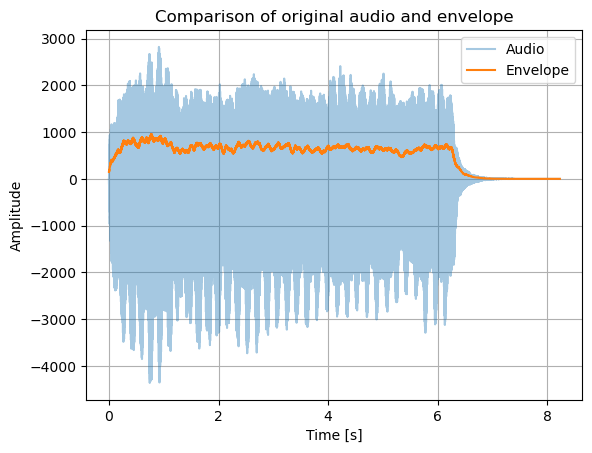

In [8]:
# make an envelope of the sampled audio to be able to extract patterns better
envelope = uniform_filter1d(np.abs(audio), size=1000)

plt.plot(time, audio, alpha=0.4, label = 'Audio')
plt.plot(time, envelope, label = 'Envelope')
plt.xlabel('Time [s]')
plt.ylabel('Amplitude')
plt.title('Comparison of original audio and envelope')
plt.grid()
plt.legend()

# finding the attack time (from the sound begins to the highest peak in amplitude)
peak_index = np.argmax(envelope)
attack_time = float(time[peak_index])
instrument_features_dic['Attack time'] = attack_time

# define the half peak (where the decay ends)
half_peak = 0.5 * np.max(envelope)

# finding the decay time
decay_index = np.where(envelope[peak_index:] <= half_peak)[0][0]

total_decay_index = peak_index + decay_index

decay_time = float(time[total_decay_index] - attack_time)
instrument_features_dic['Decay time'] = decay_time

# find sustain level
sustain_start = peak_index + decay_index

sustain = np.mean(envelope[sustain_start:])
sustain_ratio = float(sustain / np.max(envelope))
instrument_features_dic['Sustain ratio'] = sustain_ratio

# spectral centroid (the center of gravity of the sound) - finding the weight of the sound
# lower centroids is a softer, deeper sound, while higher spectral centroids gives a bright and sharp sound
centroid = float(np.sum(ffreq_pos*mag_pos) / np.sum(mag_pos))
instrument_features_dic['Spectral centroid'] = centroid

# print the dictionary
display(instrument_features_dic)

##  Some simple instrument classification system - guess whether the source is a violin, guitar, flute, piano, trumpet, etc. based on some feature vector that collects all of above metrics

to do this, I have done the process above on 5 files for each instrument to get the instrument_features_dic for all those, and then i have made a simple classification system from those.

Since this is quite a comprehensive process, I have only done it for four instruments, but it can be expanded to contain more instruments if wanted.

In [9]:
### violin ###
# A#3
# sounds\TinySOL\Strings\Violin\ordinario\Vn-ord-A#3-ff-4c-T15u.wav
instrument_features_dic_A3_violin = {'f0': 233.33333333333334,
                                    'Harmonic 2': 2.559051919658383,
                                    'Harmonic 3': 0.4891865055679228,
                                    'Harmonic 4': 0.723660657239925,
                                    'Attack time': 4.62225873697433,
                                    'Decay time': 1.5745171857504117,
                                    'Sustain ratio': 0.02527193103480692,
                                    'Spectral centroid': 3074.5227498333707,
                                    'instrument' : 'violin'}

# B4
# sounds\TinySOL\Strings\Violin\ordinario\Vn-ord-B4-pp-3c-N.wav
instrument_features_dic_B4_violin = {'f0': 490.0,
                                    'Harmonic 2': 0.03038992197260742,
                                    'Harmonic 3': 0.012921296514426597,
                                    'Harmonic 4': 0.010662639804891842,
                                    'Attack time': 4.7186765859462225,
                                    'Decay time': 0.887168250486849,
                                    'Sustain ratio': 0.15188567287590812,
                                    'Spectral centroid': 3306.5317921937117,
                                    'instrument' : 'violin'}

# C5
# sounds\TinySOL\Strings\Violin\ordinario\Vn-ord-C5-mf-2c-N.wav
instrument_features_dic_C5_violin = {'f0': 525.0,
                                    'Harmonic 2': 0.04534682862983615,
                                    'Harmonic 3': 0.01772266540404887,
                                    'Harmonic 4': 0.02460768315612696,
                                    'Attack time': 1.0533816950024766,
                                    'Decay time': 3.5292164344684087,
                                    'Sustain ratio': 0.28821553076486833,
                                    'Spectral centroid': 3731.277239203139,
                                    'instrument' : 'violin'}

# E6
# sounds\TinySOL\Strings\Violin\ordinario\Vn-ord-E6-ff-1c-N.wav
instrument_features_dic_E6_violin = {'f0': 1297.0588235294117,
                                    'Harmonic 2': 0.059155388877654626,
                                    'Harmonic 3': 0.01714705376403376,
                                    'Harmonic 4': 0.013005686315913572,
                                    'Attack time': 0.7289591287613043,
                                    'Decay time': 0.6053986630064797,
                                    'Sustain ratio': 0.3458617570396623,
                                    'Spectral centroid': 7586.596881729386,
                                    'instrument' : 'violin'}

# G#6
# sounds\TinySOL\Strings\Violin\ordinario\Vn-ord-G#6-mf-2c-T21d.wav
instrument_features_dic_G6_violin = {'f0': 1633.3333333333333,
                                    'Harmonic 2': 0.0006812385848278989,
                                    'Harmonic 3': 0.00030711850414694234,
                                    'Harmonic 4': 7.665743790057092e-05,
                                    'Attack time': 2.5429328993473566,
                                    'Decay time': 2.087602717179099,
                                    'Sustain ratio': 0.295157642016265,
                                    'Spectral centroid': 4328.322801647603,
                                    'instrument' : 'violin'}


### flute ###
# A#4
# sounds\TinySOL\Winds\Flute\ordinario\Fl-ord-A#4-ff-N-N.wav
instrument_features_dic_A4_flute = {'f0': 469.1489361702128,
                                    'Harmonic 2': 1.2368094701110417,
                                    'Harmonic 3': 0.2110302679639649,
                                    'Harmonic 4': 0.22445217938158726,
                                    'Attack time': 4.16343825038266,
                                    'Decay time': 2.2732503913296416,
                                    'Sustain ratio': 0.0969054632138807,
                                    'Spectral centroid': 2193.1987402786867,
                                    'instrument' : 'flute'}

# B4
# sounds\TinySOL\Winds\Flute\ordinario\Fl-ord-B4-ff-N-T10d.wav
instrument_features_dic_B4_flute = {'f0': 495.5056179775281,
                                    'Harmonic 2': 1.3705292127921458,
                                    'Harmonic 3': 0.39378170551179864,
                                    'Harmonic 4': 0.42278009019398993,
                                    'Attack time': 5.8048274342365795,
                                    'Decay time': 0.39251837122501865,
                                    'Sustain ratio': 0.07457249718080192,
                                    'Spectral centroid': 2407.8369457105387,
                                    'instrument' : 'flute'}

# C#5
# sounds\TinySOL\Winds\Flute\ordinario\Fl-ord-C#5-mf-N-N.wav
instrument_features_dic_C5_flute = {'f0': 558.2278481012659,
                                    'Harmonic 2': 0.05528371965479829,
                                    'Harmonic 3': 0.1105720538612626,
                                    'Harmonic 4': 0.023862167142875968,
                                    'Attack time': 3.6622582186040677,
                                    'Decay time': 2.400643652439091,
                                    'Sustain ratio': 0.07101319366468878,
                                    'Spectral centroid': 2574.788251967396,
                                    'instrument' : 'flute'}

# E6
# sounds\TinySOL\Winds\Flute\ordinario\Fl-ord-E6-ff-N-T25d.wav
instrument_features_dic_E6_flute = {'f0': 1336.3636363636363,
                                    'Harmonic 2': 0.0009336938948974416,
                                    'Harmonic 3': 0.0003557251268796342,
                                    'Harmonic 4': 0.0002576384316720603,
                                    'Attack time': 1.7009800769657026,
                                    'Decay time': 5.514823532698196,
                                    'Sustain ratio': 0.044028055461803814,
                                    'Spectral centroid': 3554.9898167676174,
                                    'instrument' : 'flute'}

# G6
# sounds\TinySOL\Winds\Flute\ordinario\Fl-ord-G6-ff-N-N.wav
instrument_features_dic_G6_flute = {'f0': 1575.0,
                                    'Harmonic 2': 0.07476824031986802,
                                    'Harmonic 3': 0.016275654516761058,
                                    'Harmonic 4': 0.0008387435780788067,
                                    'Attack time': 6.002808986378073,
                                    'Decay time': 0.4227905151838689,
                                    'Sustain ratio': 0.04458685306819575,
                                    'Spectral centroid': 3778.132306306693,
                                    'instrument' : 'flute'}


### piano ###
# A#1
# sounds\TinySOL\Keyboards\Accordion\ordinario\Acc-ord-A#1-ff-N-T12u.wav
instrument_features_dic_A1_piano = {'f0': 58.48806366047745,
                                    'Harmonic 2': 0.77567050791213,
                                    'Harmonic 3': 0.8174650296797933,
                                    'Harmonic 4': 0.556792134140883,
                                    'Attack time': 3.600329305921847,
                                    'Decay time': 0.7909323074971595,
                                    'Sustain ratio': 0.013190645217049773,
                                    'Spectral centroid': 1336.2619161987002,
                                    'instrument' : 'piano'}

# B4
# sounds\TinySOL\Keyboards\Accordion\ordinario\Acc-ord-B4-ff-alt1-N.wav
instrument_features_dic_B4_piano = {'f0': 495.5056179775281,
                                    'Harmonic 2': 0.6780730850025649,
                                    'Harmonic 3': 1.4413607481395303,
                                    'Harmonic 4': 0.3529532197231908,
                                    'Attack time': 0.30167921728666813,
                                    'Decay time': 3.076747062411626,
                                    'Sustain ratio': 0.008382929941087483,
                                    'Spectral centroid': 2883.2991740247016,
                                    'instrument' : 'piano'}

# C5
# sounds\TinySOL\Keyboards\Accordion\ordinario\Acc-ord-C5-ff-alt1-N.wav
instrument_features_dic_C5_piano = {'f0': 525.0,
                                    'Harmonic 2': 1.45407655726202,
                                    'Harmonic 3': 1.0400474343214259,
                                    'Harmonic 4': 0.12277956776135059,
                                    'Attack time': 2.806292054258181,
                                    'Decay time': 0.45911742545929046,
                                    'Sustain ratio': 0.009197560264719983,
                                    'Spectral centroid': 2002.30826537637,
                                    'instrument' : 'piano'}

# E6
# sounds\TinySOL\Keyboards\Accordion\ordinario\Acc-ord-E6-ff-alt1-N.wav
instrument_features_dic_E6_piano = {'f0': 1336.3636363636363,
                                    'Harmonic 2': 0.00044658908576815457,
                                    'Harmonic 3': 5.261465383392471e-05,
                                    'Harmonic 4': 0.00012660671694703988,
                                    'Attack time': 0.5590946767430897,
                                    'Decay time': 3.811757664307263,
                                    'Sustain ratio': 0.011110674487251957,
                                    'Spectral centroid': 3768.217181930078,
                                    'instrument' : 'piano'}

# G#6
# sounds\TinySOL\Keyboards\Accordion\ordinario\Acc-ord-G#6-ff-alt1-N.wav
instrument_features_dic_G6_piano = {'f0': 1696.1538461538462,
                                    'Harmonic 2': 5.3168801379520465e-05,
                                    'Harmonic 3': 2.9195657198503877e-05,
                                    'Harmonic 4': 1.6396220895061784e-05,
                                    'Attack time': 0.856284081855265,
                                    'Decay time': 3.7535047874958996,
                                    'Sustain ratio': 0.01936110774587248,
                                    'Spectral centroid': 4764.982474692349,
                                    'instrument' : 'piano'}


### trumpet ###
# A#3
# sounds\TinySOL\Brass\Trumpet_C\ordinario\TpC-ord-A#3-ff-N-T23u_R100u.wav
instrument_features_dic_A3_trumpet = {'f0': 233.33333333333334,
                                    'Harmonic 2': 0.6228740935347468,
                                    'Harmonic 3': 0.7459623351914199,
                                    'Harmonic 4': 0.6754186170656289,
                                    'Attack time': 0.3733574295552686,
                                    'Decay time': 5.127185039895698,
                                    'Sustain ratio': 0.059189056190416076,
                                    'Spectral centroid': 6668.348627242355,
                                    'instrument' : 'trumpet'}

# B4
# sounds\TinySOL\Brass\Trumpet_C\ordinario\TpC-ord-B4-ff-N-N.wav
instrument_features_dic_B4_trumpet = {'f0': 495.5056179775281,
                                    'Harmonic 2': 0.36576588811582095,
                                    'Harmonic 3': 0.39381043079426825,
                                    'Harmonic 4': 0.3443923023839482,
                                    'Attack time': 0.19124782959937262,
                                    'Decay time': 5.822537224296858,
                                    'Sustain ratio': 0.04790524717953628,
                                    'Spectral centroid': 5146.623372944649,
                                    'instrument' : 'trumpet'}

# C5
# sounds\TinySOL\Brass\Trumpet_C\ordinario\TpC-ord-C5-ff-N-N.wav
instrument_features_dic_C5_trumpet = {'f0': 518.8235294117648,
                                    'Harmonic 2': 0.5175666398425172,
                                    'Harmonic 3': 0.40913684202184014,
                                    'Harmonic 4': 0.3335759941340841,
                                    'Attack time': 1.7110943408311012,
                                    'Decay time': 4.372123932939008,
                                    'Sustain ratio': 0.044763342380274476,
                                    'Spectral centroid': 5335.12599547845,
                                    'instrument' : 'trumpet'}

# E5
# sounds\TinySOL\Brass\Trumpet_C\ordinario\TpC-ord-E5-ff-N-N.wav
instrument_features_dic_E5_trumpet = {'f0': 658.2089552238806,
                                    'Harmonic 2': 0.5612405461690065,
                                    'Harmonic 3': 0.3777462237144924,
                                    'Harmonic 4': 0.2376676737179971,
                                    'Attack time': 0.26476286201866855,
                                    'Decay time': 5.532741092199469,
                                    'Sustain ratio': 0.06175276369139068,
                                    'Spectral centroid': 4664.917066384372,
                                    'instrument' : 'trumpet'}

# G#5
# sounds\TinySOL\Brass\Trumpet_C\ordinario\TpC-ord-G#5-pp-N-T23d.wav
instrument_features_dic_G5_trumpet = {'f0': 832.0754716981132,
                                    'Harmonic 2': 0.0450452249023112,
                                    'Harmonic 3': 0.01099295091795791,
                                    'Harmonic 4': 0.0027120487514159706,
                                    'Attack time': 1.0232913940818722,
                                    'Decay time': 5.063282189920474,
                                    'Sustain ratio': 0.039366268746900086,
                                    'Spectral centroid': 2209.2484064596083,
                                    'instrument' : 'trumpet'}

In [10]:
# make dataset of the dictionaries defines above
sounds_dataset = [instrument_features_dic_A3_violin,
                  instrument_features_dic_B4_violin,
                  instrument_features_dic_C5_violin,
                  instrument_features_dic_E6_violin,
                  instrument_features_dic_G6_violin,

                  instrument_features_dic_A4_flute,
                  instrument_features_dic_B4_flute,
                  instrument_features_dic_C5_flute,
                  instrument_features_dic_E6_flute,
                  instrument_features_dic_G6_flute,

                  instrument_features_dic_A1_piano,
                  instrument_features_dic_B4_piano,
                  instrument_features_dic_C5_piano,
                  instrument_features_dic_E6_piano,
                  instrument_features_dic_G6_violin,

                  instrument_features_dic_A3_trumpet,
                  instrument_features_dic_B4_trumpet,
                  instrument_features_dic_C5_trumpet,
                  instrument_features_dic_E5_trumpet,
                  instrument_features_dic_G5_trumpet]

# empty lists that is to be used to make algorithm
X = []
y = []

# make X a list, and for each iteration, it contains the full relevant data for each instrument
# y contains the type of instrument
for sample in sounds_dataset:
    X.append([
        sample['Harmonic 2'],
        sample['Harmonic 3'],
        sample['Harmonic 4'],
        sample['Attack time'],
        sample['Decay time'],
        sample['Sustain ratio'],
        sample['Spectral centroid']])

    y.append(sample['instrument'])

scaler = StandardScaler()

# normalise each sample to have mean=0 and std=1 - this is necessary to do ML on the data 
X_scaled = scaler.fit_transform(X)

# making the model. Using k nearest neighbors, where K=1 since it is quite a small dataset.
model = KNeighborsClassifier(n_neighbors=1)

# making the model adjust to the given data
model.fit(X_scaled, y)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",1
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[<U7](4,)","['flute','piano','trumpet','violin']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [11]:
# now the classification of the current instrument.
# first, make a list of the features of the current instrument
test = [[
    instrument_features_dic['Harmonic 2'],
    instrument_features_dic['Harmonic 3'],
    instrument_features_dic['Harmonic 4'],
    instrument_features_dic['Attack time'],
    instrument_features_dic['Decay time'],
    instrument_features_dic['Sustain ratio'],
    instrument_features_dic['Spectral centroid']
    ]]

# scale
test_scaled = scaler.transform(test)

# usind the model to predict the instrument
prediction = model.predict(test_scaled)

print(prediction[0])

violin


# summary of results

In [12]:
print('*'*50)
print(f'This audio plays an {instrument_features_dic["f0"]:.2f} Hz tone, which corresponds to the note {closest_note}, with a deviation of {cents:.2f} cents.')
print(f'The instrument being played is {prediction[0]}')
print('*'*50)

**************************************************
This audio plays an 247.75 Hz tone, which corresponds to the note B3, with a deviation of 5.69 cents.
The instrument being played is violin
**************************************************
